# 02 · Контент и драйверы продаж: что действительно связано с заказом

**Отвечает на вопросы кейса №2 и №3:** что мешает расти и какие инструменты дадут эффект.
**Методологическое требование кейса:** *«Только сначала проверь, насколько группы сопоставимы.
Нам нужны data-driven выводы, а не просто несколько красивых графиков»*.

## План
1. Товарный контент vs обычный: **парное сравнение внутри одного сообщества** (контроль размера аудитории).
2. Парадокс агрегата (эффект Симпсона) — почему «товарный контент хуже» верно и неверно одновременно.
3. Где рвётся контентная воронка: просмотр → открытие карточки.
4. **Логит** активации: odds ratios с доверительными интервалами.
5. **PSM** (сопоставление по propensity score): честная оценка «эффекта доставки».
6. **ML** (градиентный бустинг): что предсказывает продажу, важность признаков.
7. Что из этого — рычаг для продукта, а что — просто корреляция.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vkcase import data, analysis as an, viz
from vkcase.config import VK, PARTNER, GOOD, BAD, GREY

pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 60)
%matplotlib inline

d = data.load_all()
b = an.add_scenario_segment(d["biz"])

## 1. Товарный контент: сколько его и что он даёт

В кейсе Максим утверждает: *«Товарный контент распространяется хуже обычного»*.
Проверяем это утверждение на данных, а не принимаем на веру.

In [2]:
overview = pd.DataFrame([
    ["Публикаций всего (посты + клипы)", b.content_all.sum()],
    ["Публикаций с товаром", b.content_prod.sum()],
    ["Просмотров обычного контента", b.views_reg.sum()],
    ["Просмотров товарного контента", b.views_prod.sum()],
    ["Сообществ, публикующих товарный контент", int((b.content_prod > 0).sum())],
    ["Сообществ с открытиями карточки из контента", int((b.card_opens > 0).sum())],
], columns=["показатель", "значение"])
overview["доля"] = [np.nan, b.content_prod.sum()/b.content_all.sum(), np.nan,
                    b.views_prod.sum()/b.views_all.sum(),
                    (b.content_prod > 0).mean(), (b.card_opens > 0).mean()]
data.save_table(overview, "02_content_overview")
overview

,показатель,значение,доля
0,Публикаций всего (посты + клипы),199079,NaN
1,Публикаций с товаром,17946,0.090145
2,Просмотров обычного контента,316187622,NaN
3,Просмотров товарного контента,18366709,0.054899
4,"Сообществ, публикующих товарный контент",303,0.031064
5,Сообществ с открытиями карточки из контента,437,0.044802


Товарный контент — **9% публикаций и 5,5% просмотров**. Уже отсюда видно,
что в агрегате товарные публикации получают меньше просмотров на штуку.
Но агрегат обманчив: его формируют крупные сообщества. Смотрим парно.

In [3]:
paired, st = an.content_paired(b)
paired_org, st_org = an.content_paired(b, organic_only=True)
res = pd.DataFrame([
    {"метрика": "Просмотров на публикацию: товарный", "все пары": st["vpp_prod_median"], "без рекламодателей": st_org["vpp_prod_median"]},
    {"метрика": "Просмотров на публикацию: обычный", "все пары": st["vpp_reg_median"], "без рекламодателей": st_org["vpp_reg_median"]},
    {"метрика": "Отношение (товарный / обычный), медиана пар", "все пары": st["vpp_ratio_median"], "без рекламодателей": st_org["vpp_ratio_median"]},
    {"метрика": "Доля пар, где товарный ХУЖЕ по охвату", "все пары": st["vpp_prod_worse_share"], "без рекламодателей": st_org["vpp_prod_worse_share"]},
    {"метрика": "ER (лайки+репосты)/просмотры: товарный", "все пары": st["er_prod_median"], "без рекламодателей": st_org["er_prod_median"]},
    {"метрика": "ER: обычный", "все пары": st["er_reg_median"], "без рекламодателей": st_org["er_reg_median"]},
    {"метрика": "Отношение ER (товарный / обычный), медиана пар", "все пары": st["er_ratio_median"], "без рекламодателей": st_org["er_ratio_median"]},
    {"метрика": "Доля пар, где товарный ХУЖЕ по вовлечению", "все пары": st["er_prod_worse_share"], "без рекламодателей": st_org["er_prod_worse_share"]},
])
data.save_table(res, "02_content_paired")
print(f"Пар в тесте: {st['n_paired']} (без рекламодателей: {st_org['n_paired']})")
print(f"Wilcoxon p (охват): {st['vpp_wilcoxon_p']:.2g} | (вовлечение): {st['er_wilcoxon_p']:.2g}")
res.round(4)

Пар в тесте: 299 (без рекламодателей: 250)
Wilcoxon p (охват): 4.1e-15 | (вовлечение): 4.1e-22


,метрика,все пары,без рекламодателей
0,Просмотров на публикацию: товарный,702.1277,600.0000
1,Просмотров на публикацию: обычный,375.0000,314.8707
2,"Отношение (товарный / обычный), медиана пар",1.9000,1.9660
3,"Доля пар, где товарный ХУЖЕ по охвату",0.2977,0.2880
4,ER (лайки+репосты)/просмотры: товарный,0.0100,0.0111
5,ER: обычный,0.0155,0.0188
6,"Отношение ER (товарный / обычный), медиана пар",0.5411,0.5434
7,"Доля пар, где товарный ХУЖЕ по вовлечению",0.7258,0.7200


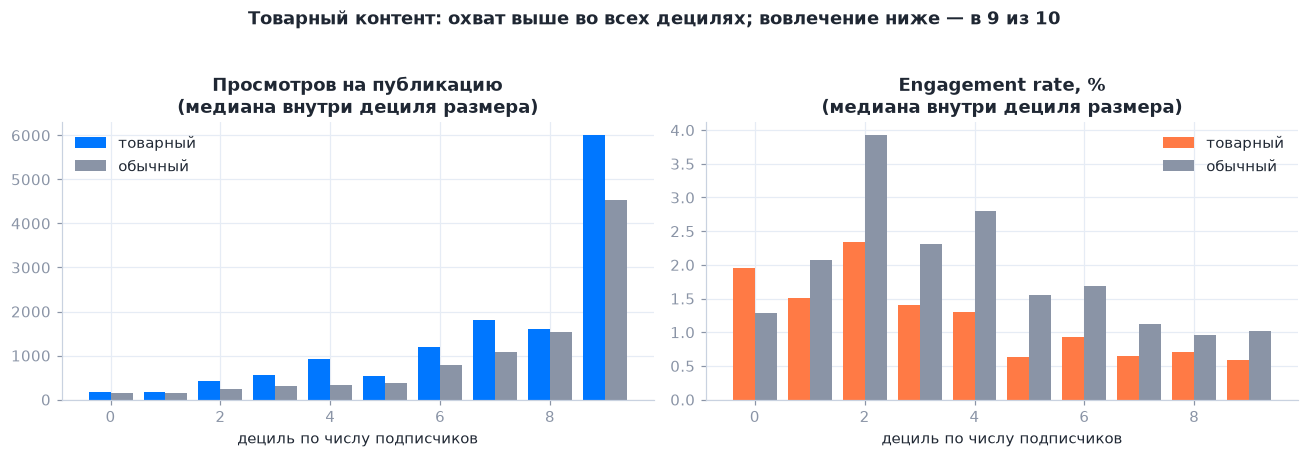

,size_decile,n,subs_median,vpp_prod,vpp_reg,er_prod,er_reg,card_ctr,vpp_ratio,er_ratio
0,1,31,36.0,180.0000,140.0000,0.0196,0.0129,0.0025,1.2857,1.5177
1,2,29,110.0,166.6667,145.0000,0.0151,0.0207,0.0000,1.1494,0.7319
2,3,30,260.0,428.3333,252.0243,0.0234,0.0392,0.0019,1.6996,0.5954
3,4,31,560.0,550.0000,306.2500,0.0140,0.0232,0.0019,1.7959,0.6034
4,5,29,890.0,930.0000,329.1667,0.0130,0.0279,0.0015,2.8253,0.4668
5,6,30,1400.0,545.0000,368.0556,0.0063,0.0155,0.0017,1.4808,0.4077
6,7,31,2300.0,1200.0000,793.1034,0.0093,0.0169,0.0013,1.5130,0.5535
7,8,30,4750.0,1800.0000,1090.9091,0.0065,0.0112,0.0012,1.6500,0.5826
8,9,31,9000.0,1600.0000,1542.8571,0.0071,0.0095,0.0012,1.0370,0.7495
9,10,27,26000.0,6000.0000,4528.3019,0.0059,0.0101,0.0010,1.3250,0.5830


In [4]:
by_dec = st["by_decile"]
data.save_table(by_dec, "02_content_by_decile")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(by_dec)); w = 0.4
axes[0].bar(x - w/2, by_dec.vpp_prod, w, label="товарный", color=VK)
axes[0].bar(x + w/2, by_dec.vpp_reg, w, label="обычный", color=GREY)
axes[0].set_title("Просмотров на публикацию\n(медиана внутри дециля размера)")
axes[0].set_xlabel("дециль по числу подписчиков"); axes[0].legend()
axes[1].bar(x - w/2, by_dec.er_prod * 100, w, label="товарный", color=PARTNER)
axes[1].bar(x + w/2, by_dec.er_reg * 100, w, label="обычный", color=GREY)
axes[1].set_title("Engagement rate, %\n(медиана внутри дециля размера)")
axes[1].set_xlabel("дециль по числу подписчиков"); axes[1].legend()
fig.suptitle("Товарный контент: охват выше во всех децилях; вовлечение ниже — в 9 из 10", fontweight="bold", y=1.03)
fig.tight_layout(); viz.save(fig, "02_content_by_decile")
by_dec.round(4)

### 2.1. Эффект Симпсона: почему агрегат и парный тест противоречат друг другу

Это ровно тот случай, когда «красивый график» ведёт к неверному решению.

In [5]:
simpson = pd.DataFrame([
    ["Агрегат по всей выборке (взвешен крупными)", st["vpp_agg_prod"], st["vpp_agg_reg"],
     st["vpp_agg_prod"] / st["vpp_agg_reg"]],
    ["Медиана парных отношений (внутри сообщества)", st["vpp_prod_median"], st["vpp_reg_median"], st["vpp_ratio_median"]],
    ["Медиана парных отношений, только органика", st_org["vpp_prod_median"], st_org["vpp_reg_median"], st_org["vpp_ratio_median"]],
], columns=["способ расчёта", "просмотров/публикация: товарный", "просмотров/публикация: обычный", "отношение"])
data.save_table(simpson, "02_simpson")
simpson.round(3)

,способ расчёта,просмотров/публикация: товарный,просмотров/публикация: обычный,отношение
0,Агрегат по всей выборке (взвешен крупными),1023.443,1588.252,0.644
1,Медиана парных отношений (внутри сообщества),702.128,375.000,1.900
2,"Медиана парных отношений, только органика",600.000,314.871,1.966


In [6]:
big = b[b.subs >= b.subs.quantile(0.99)]
small = b[b.subs < b.subs.quantile(0.99)]
print(f"Топ-1% по подписчикам: доля товарных публикаций {big.content_prod.sum()/big.content_all.sum():.2%}, "
      f"доля товарных просмотров {big.views_prod.sum()/big.views_all.sum():.2%}")
print(f"Остальные 99%: доля товарных публикаций {small.content_prod.sum()/small.content_all.sum():.2%}, "
      f"доля товарных просмотров {small.views_prod.sum()/small.views_all.sum():.2%}")

Топ-1% по подписчикам: доля товарных публикаций 1.17%, доля товарных просмотров 2.99%
Остальные 99%: доля товарных публикаций 9.66%, доля товарных просмотров 6.70%


> **Вывод, который важно защитить перед жюри.**
> Утверждение «товарный контент распространяется хуже» **не подтверждается на уровне сообщества**:
> у одного и того же автора товарная публикация собирает **≈в 1,9 раза больше просмотров**,
> и это устойчиво во всех децилях размера и без рекламодателей.
> Но **вовлечение (ER) у товарного контента ниже примерно в 1,8 раза** (72,6% сообществ).
>
> Значит проблема не в «алгоритм не даёт охват», а в том, что **товарный контент хуже конвертирует
> внимание в действие**. Рычаг — не «дать больше охвата», а **формат и CTA карточки в контенте**.

## 3. Где рвётся контентная воронка

Просмотр товарного контента → открытие карточки товара.

In [7]:
has_both = b[(b.views_prod > 0) & (b.card_opens > 0)]
ctr_agg = b.card_opens.sum() / b.views_prod.sum()
ctr_agg_valid = has_both.card_opens.sum() / has_both.views_prod.sum()
print(f"CTR карточки из товарного контента (агрегат по всем): {ctr_agg:.3%}")
print(f"CTR там, где есть и просмотры, и открытия (n={len(has_both)}): {ctr_agg_valid:.3%}")
print(f"Медианный CTR по сообществам с обоими событиями: {has_both.card_ctr.median():.3%}")
print(f"\nДля сравнения, платформенный CTR показ→открытие Маркета: {d['totals'].loc['Конверсия: показ → открытие карточки, %','Маркет Вконтакте']}%")
print(f"Платформенный CTR показ→открытие Партнёра: {d['totals'].loc['Конверсия: показ → открытие карточки, %','Партнёр 1']}%")

CTR карточки из товарного контента (агрегат по всем): 0.289%
CTR там, где есть и просмотры, и открытия (n=397): 0.293%
Медианный CTR по сообществам с обоими событиями: 0.357%

Для сравнения, платформенный CTR показ→открытие Маркета: 4.05%
Платформенный CTR показ→открытие Партнёра: 1.52%


In [8]:
opens = b[b.card_opens > 0].copy()
opens["orders_per_1k_opens"] = 1000 * opens.orders / opens.card_opens
print(f"Сообществ с открытиями карточки из контента: {len(opens)}")
print(f"Из них с заказом: {int(opens.has_order.sum())} ({opens.has_order.mean():.1%})")
print(f"Заказов на 1000 открытий карточки (агрегат): {1000*opens.orders.sum()/opens.card_opens.sum():.2f}")
print(f"Медиана по сообществам: {opens.orders_per_1k_opens.median():.2f}")
data.save_table(opens[["biz_id", "theme", "segment", "views_prod", "card_opens", "card_ctr", "orders", "orders_per_1k_opens"]]
                .sort_values("card_opens", ascending=False), "02_content_to_card")
opens.nlargest(8, "card_opens")[["biz_id", "theme", "content_prod", "views_prod", "card_opens", "card_ctr", "orders"]]

Сообществ с открытиями карточки из контента: 437
Из них с заказом: 79 (18.1%)
Заказов на 1000 открытий карточки (агрегат): 21.76
Медиана по сообществам: 0.00


,biz_id,theme,content_prod,views_prod,card_opens,card_ctr,orders
4,6398,Личный блог,19,1100000,10859,0.009872,0
0,9308,Мода и стиль,23,3800000,8372,0.002203,0
2,5330,Образование,26,1300000,6749,0.005192,83
1,3078,Спорт,7,2300000,5818,0.002530,0
12,4480,Услуги,26,300000,4783,0.015943,7
9,2932,Личный блог,4,440000,3711,0.008434,0
6,2,Путешествия и отдых,23,540000,1268,0.002348,0
7,134,Образование,1,490000,796,0.001624,0


**Ключевая цифра:** из контента в карточку переходит **менее 0,3%** просмотров товарного контента.
Даже у сообществ, где открытия есть, медианный CTR — доли процента.
При этом сообществ, которые вообще публикуют товарный контент, — **3,1%**.

Два независимых рычага:
1. **Расширить использование шопсов** (сейчас 3% сообществ) — количественный рычаг.
2. **Поднять CTR карточки в контенте** — качественный рычаг (формат, цена/скидка в креативе, CTA, «купить в 1 клик»).

## 4. Логит: что связано с фактом первой продажи

Модель P(≥1 заказ) на подвыборке с каталогом (n≈3 961). Логарифмы — из-за сильной асимметрии.

**Осторожно с интерпретацией `checkout`:** заказы у нас измеряются «через чекаут»,
поэтому без чекаута заказ физически не может быть учтён. Коэффициент чекаута — **почти тавтология**,
> а не эффект инструмента. Его нельзя использовать как аргумент «включим чекаут — вырастут продажи в 8 раз».

In [9]:
logit, info = an.logit_activation(b, only_catalog=True)
data.save_table(logit, "02_logit_activation")
print(f"n={info['n']}, базовая доля продающих={info['base_rate']:.2%}, pseudo-R²={info['pseudo_r2']:.3f}")
lg = logit[logit.feature != "const"].copy()
lg["значимость"] = np.where(lg.p_value < 0.01, "***", np.where(lg.p_value < 0.05, "**", np.where(lg.p_value < 0.1, "*", "нет")))
lg[["feature", "odds_ratio", "ci_low", "ci_high", "p_value", "значимость"]].round(3)

n=3961, базовая доля продающих=7.20%, pseudo-R²=0.222


,feature,odds_ratio,ci_low,ci_high,p_value,значимость
1,log_subs,1.192,1.067,1.332,0.002,***
2,log_sku,1.515,1.391,1.651,0.000,***
3,log_content,0.807,0.705,0.923,0.002,***
4,log_views_reg,1.448,1.300,1.613,0.000,***
5,has_prod_content,1.507,0.963,2.360,0.073,*
6,checkout,8.271,3.690,18.537,0.000,***
7,delivery,1.588,1.179,2.139,0.002,***
8,payment,1.136,0.707,1.824,0.598,нет
9,log_ad_spend,1.020,0.982,1.059,0.314,нет
10,referral,1.141,0.602,2.163,0.685,нет


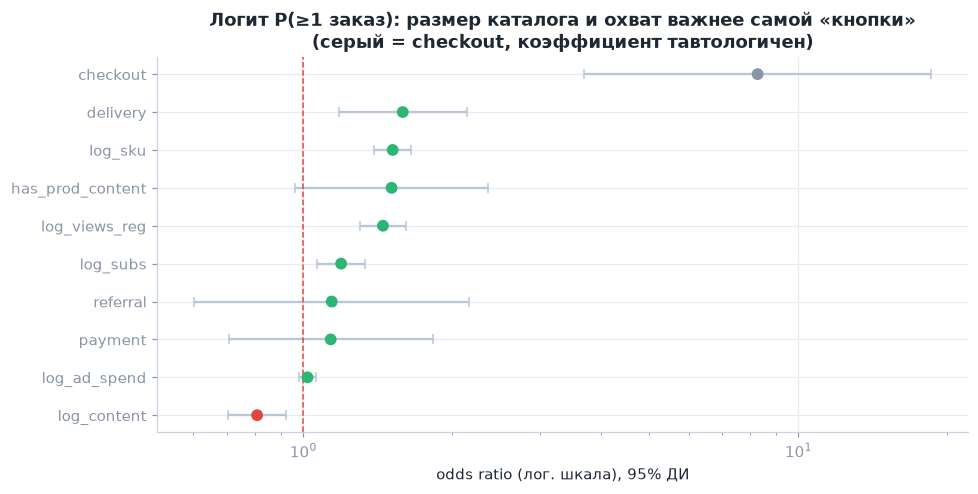

WindowsPath('C:/Users/Степан/Desktop/workspace/outputs/figures/02_logit_forest.png')

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.6))
plot_df = lg.sort_values("odds_ratio")
colors = [GREY if f == "checkout" else (GOOD if o > 1 else BAD) for f, o in zip(plot_df.feature, plot_df.odds_ratio)]
ax.errorbar(plot_df.odds_ratio, np.arange(len(plot_df)),
            xerr=[plot_df.odds_ratio - plot_df.ci_low, plot_df.ci_high - plot_df.odds_ratio],
            fmt="o", color=VK, ecolor="#B9C6DA", capsize=3, ms=5)
ax.scatter(plot_df.odds_ratio, np.arange(len(plot_df)), c=colors, s=45, zorder=3)
ax.axvline(1, color=BAD, ls="--", lw=1)
ax.set_yticks(np.arange(len(plot_df)), plot_df.feature)
ax.set_xscale("log")
ax.set_xlabel("odds ratio (лог. шкала), 95% ДИ")
ax.set_title("Логит P(≥1 заказ): размер каталога и охват важнее самой «кнопки»\n(серый = checkout, коэффициент тавтологичен)")
fig.tight_layout(); viz.save(fig, "02_logit_forest")

**Что читаем:**
* `log_sku` OR≈1,52 — **ассортимент** самый сильный содержательный предиктор: рост каталога в e раз
  повышает шансы продажи примерно в 1,5 раза;
* `log_views_reg` OR≈1,45 — важен **общий охват сообщества**, а не только товарный;
* `log_content` OR≈0,81 — при фиксированном охвате **больше публикаций = ниже шансы**:
  количество постов без качества размывает охват;
* `delivery` OR≈1,59 (p<0,01) — доставка значима, но эффект в разы меньше «наивного» ×3,2;
* `log_ad_spend` OR≈1,02 (p=0,31) — **траты на рекламу статистически не связаны** с фактом продажи;
* `referral`, `payment` — незначимы (мало наблюдений: рефералка у 2%, оплата у 2,6%).

In [11]:
ols, ols_info = an.ols_order_volume(b)
data.save_table(ols, "02_ols_order_volume")
print(f"OLS log1p(orders), n={ols_info['n']}, R²={ols_info['r2']:.3f} (HC3-робастные ошибки)")
ols[ols.feature != "const"].assign(эффект_процентов=lambda x: (np.exp(x.coef)-1)*100).round(3)

OLS log1p(orders), n=3961, R²=0.133 (HC3-робастные ошибки)


,feature,coef,ci_low,ci_high,p_value,эффект_процентов
1,log_subs,0.030,0.020,0.040,0.000,3.050
2,log_sku,0.064,0.049,0.078,0.000,6.559
3,log_content,0.007,-0.011,0.026,0.453,0.710
4,log_views_reg,0.027,0.017,0.037,0.000,2.735
5,has_prod_content,0.108,0.005,0.212,0.041,11.454
6,checkout,0.171,0.126,0.215,0.000,18.620
7,delivery,0.052,0.002,0.102,0.043,5.322
8,payment,-0.000,-0.087,0.086,0.994,-0.033
9,log_ad_spend,-0.000,-0.009,0.008,0.918,-0.043
10,referral,0.070,-0.088,0.228,0.385,7.238


## 5. PSM: честная оценка «эффекта доставки»

Наивное сравнение: сообщества с доставкой продают в 3,2 раза чаще.
Но у них в 4 раза больше каталог. Сопоставляем **похожие** сообщества по propensity score
(размер, каталог, активность, охват, товарный контент, реклама), 1:1, с калипером.

In [12]:
psm = an.psm_effect(b, treatment="delivery", restrict={"checkout": 1}, n_boot=400)
print(f"Леченых (доставка есть): {psm['n_treated']} | пул контроля: {psm['n_control_pool']} | сопоставленных пар: {psm['n_matched_pairs']}")
data.save_table(psm["effects"], "02_psm_delivery_effects")
data.save_table(psm["balance"], "02_psm_delivery_balance")
psm["effects"].round(3)

Леченых (доставка есть): 719 | пул контроля: 2922 | сопоставленных пар: 714


,outcome,treated_naive,control_naive,naive_ratio,treated_matched,control_matched,ATT,ATT_ci_low,ATT_ci_high,matched_ratio
0,sell_rate,0.171,0.053,3.225,0.167,0.134,0.032,-0.004,0.071,1.240
1,orders_per_biz,2.229,0.624,3.574,2.196,2.791,-0.595,-2.707,1.245,0.787
2,gmv_per_biz,7328.161,1449.124,5.057,7018.569,5714.776,1303.793,-2884.978,5833.563,1.228


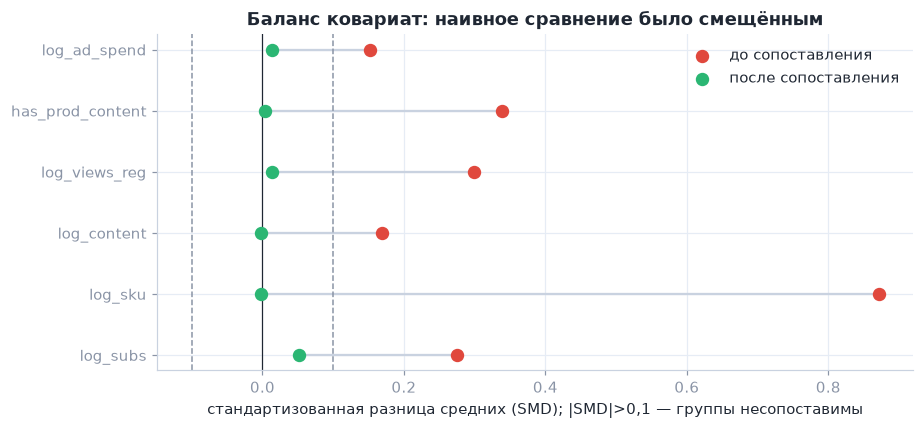

,feature,SMD_before,SMD_after
0,log_subs,0.275,0.052
1,log_sku,0.871,-0.002
2,log_content,0.169,-0.003
3,log_views_reg,0.299,0.014
4,has_prod_content,0.339,0.004
5,log_ad_spend,0.152,0.013


In [13]:
bal = psm["balance"]
fig, ax = plt.subplots(figsize=(8.5, 4))
y = np.arange(len(bal))
ax.scatter(bal.SMD_before, y, label="до сопоставления", color=BAD, s=60, zorder=3)
ax.scatter(bal.SMD_after, y, label="после сопоставления", color=GOOD, s=60, zorder=3)
for i, (a, bb) in enumerate(zip(bal.SMD_before, bal.SMD_after)):
    ax.plot([a, bb], [i, i], color="#C9D2E0", lw=1.5, zorder=2)
ax.axvline(0.1, color=GREY, ls="--", lw=1); ax.axvline(-0.1, color=GREY, ls="--", lw=1)
ax.axvline(0, color="#1F2733", lw=0.8)
ax.set_yticks(y, bal.feature)
ax.set_xlabel("стандартизованная разница средних (SMD); |SMD|>0,1 — группы несопоставимы")
ax.set_title("Баланс ковариат: наивное сравнение было смещённым")
ax.legend()
fig.tight_layout(); viz.save(fig, "02_psm_balance")
bal.round(3)

In [14]:
eff = psm["effects"].set_index("outcome")
sr = eff.loc["sell_rate"]
print(f"Доля продающих: наивно {sr.treated_naive:.1%} vs {sr.control_naive:.1%} (×{sr.naive_ratio:.2f})")
print(f"После сопоставления: {sr.treated_matched:.1%} vs {sr.control_matched:.1%} (×{sr.matched_ratio:.2f})")
print(f"ATT = {sr.ATT*100:+.2f} п.п., 95% ДИ [{sr.ATT_ci_low*100:+.2f}; {sr.ATT_ci_high*100:+.2f}] п.п.")
print(f"Заказов на сообщество: ATT = {eff.loc['orders_per_biz','ATT']:+.2f} "
      f"(ДИ [{eff.loc['orders_per_biz','ATT_ci_low']:+.2f}; {eff.loc['orders_per_biz','ATT_ci_high']:+.2f}])")

Доля продающих: наивно 17.1% vs 5.3% (×3.22)
После сопоставления: 16.7% vs 13.4% (×1.24)
ATT = +3.22 п.п., 95% ДИ [-0.42; +7.14] п.п.
Заказов на сообщество: ATT = -0.60 (ДИ [-2.71; +1.24])


> **Главный методологический вывод кейса.**
> Наивный «эффект доставки» ×3,2 **на 3/4 объясняется размером каталога и аудитории**.
> После сопоставления остаётся ≈×1,2 по вероятности первой продажи, и доверительный интервал
> ATT включает ноль → **эффект направления положительный, но статистически не доказан**.
> По объёму заказов эффекта не видно вовсе.
>
> Что это значит для решения: **подключение доставки — необходимое, но недостаточное условие**.
> Нельзя обещать жюри «подключим доставку — продажи вырастут втрое». Правильная формулировка:
> «доставка снимает барьер исполнения заказа; ожидаемый прирост активации — единицы процентных пунктов,
> проверяем A/B-тестом на пилоте».

## 6. ML: что предсказывает продажу (важность ≠ причинность)

Градиентный бустинг, 5-fold кросс-валидация. Метрики для несбалансированного таргета:
ROC-AUC и **average precision** (базовая доля продающих ≈7%).

n=3961 | ROC-AUC=0.836 | Average Precision=0.394 (база 0.072)


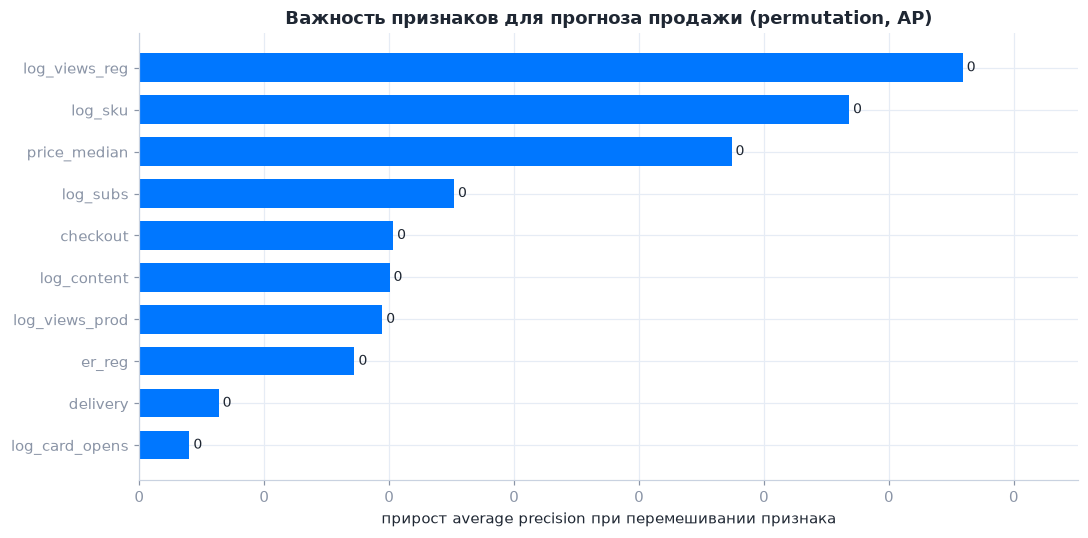

,feature,importance,std
3,log_views_reg,0.3295,0.0176
1,log_sku,0.2840,0.0195
14,price_median,0.2370,0.0164
0,log_subs,0.1259,0.0161
7,checkout,0.1015,0.0150
2,log_content,0.1001,0.0075
4,log_views_prod,0.0972,0.0099
13,er_reg,0.0861,0.0068
8,delivery,0.0317,0.0046
5,log_card_opens,0.0200,0.0039


In [15]:
ml = an.ml_drivers(b, only_catalog=True)
print(f"n={ml['n']} | ROC-AUC={ml['auc']:.3f} | Average Precision={ml['ap']:.3f} (база {ml['base_rate']:.3f})")
data.save_table(ml["importance"], "02_ml_importance")
viz.hbar(ml["importance"].head(10), "feature", "importance",
         "Важность признаков для прогноза продажи (permutation, AP)", "02_ml_importance",
         color=VK, xlabel="прирост average precision при перемешивании признака")
ml["importance"].head(10).round(4)

Модель уверенно отделяет продающие сообщества (AUC≈0,84), и топ-признаки — **ассортимент,
охват, цена товара, размер аудитории**. Инструменты (`checkout`, `delivery`) дают меньший вклад,
чем «есть что продавать и кому показать». Это согласуется с логитом и PSM.

## 7. Свод: рычаг → доказательство → ожидаемый эффект → как проверить

Именно эту таблицу стоит вынести в приложение к презентации.

In [16]:
levers = pd.DataFrame([
    ["Наполнение каталога (импорт из маркетплейса, карточка из фото)",
     "log_sku OR≈1,52 (p<0,001); топ-1 важность в ML; у продающих медиана каталога в 4 раза выше",
     "рост вероятности первой продажи; сильнее всего у S2/S4",
     "A/B: автоимпорт каталога при онбординге; метрика — доля сообществ с ≥1 заказом за 30 дней"],
    ["Доставка «из коробки» + оплата внутри VK",
     "наивно ×3,2 → PSM ×1,2 (ATT +3 п.п., ДИ включает 0); логит OR≈1,59 (p<0,01)",
     "снятие барьера исполнения; единицы п.п. активации",
     "A/B на S4: дефолтная доставка vs текущий сценарий; метрики — активация, заказы, отмены"],
    ["Шопсы: товарные карточки в постах/клипах",
     "товарный контент публикуют 3,1%; CTR в карточку <0,3%; ER товарного контента ниже в 1,8 раза",
     "новый интентный трафик в карточку; сейчас почти не используется",
     "A/B формата креатива (цена/скидка/CTA); метрика — CTR просмотр→карточка и заказ/1000 открытий"],
    ["Реклама на карточку товара (вместо рекламы сообщества)",
     "log_ad_spend OR≈1,02 (p=0,31); 92% плательщиков без измеримых заказов",
     "перераспределение бюджета в измеримый результат; удержание рекламодателя",
     "A/B: цель кампании «заказ в чекауте» vs «охват»; метрика — ROAS и retention бюджета"],
    ["Реферальная программа / авторы",
     "в выборке участвуют 2%, значимого эффекта нет (мало данных); на платформе 94,8% открытий Партнёра — реферальные",
     "потенциально большой канал, но в выборке не проверяем",
     "пилот с 200 авторами; метрика — заказы на 1000 открытий и стоимость привлечённого заказа"],
], columns=["рычаг", "доказательство из данных", "ожидаемый эффект", "как проверяем"])
data.save_table(levers, "02_levers_evidence")
levers

,рычаг,доказательство из данных,ожидаемый эффект,как проверяем
0,"Наполнение каталога (импорт из маркетплейса, к...","log_sku OR≈1,52 (p<0,001); топ-1 важность в ML...",рост вероятности первой продажи; сильнее всего...,A/B: автоимпорт каталога при онбординге; метри...
1,Доставка «из коробки» + оплата внутри VK,"наивно ×3,2 → PSM ×1,2 (ATT +3 п.п., ДИ включа...",снятие барьера исполнения; единицы п.п. активации,A/B на S4: дефолтная доставка vs текущий сцена...
2,Шопсы: товарные карточки в постах/клипах,"товарный контент публикуют 3,1%; CTR в карточк...",новый интентный трафик в карточку; сейчас почт...,A/B формата креатива (цена/скидка/CTA); метрик...
3,Реклама на карточку товара (вместо рекламы соо...,"log_ad_spend OR≈1,02 (p=0,31); 92% плательщико...",перераспределение бюджета в измеримый результа...,A/B: цель кампании «заказ в чекауте» vs «охват...
4,Реферальная программа / авторы,"в выборке участвуют 2%, значимого эффекта нет ...","потенциально большой канал, но в выборке не пр...",пилот с 200 авторами; метрика — заказы на 1000...


In [17]:
data.save_key_numbers({
    "prod_content_share_of_posts": float(b.content_prod.sum() / b.content_all.sum()),
    "prod_content_share_of_views": float(b.views_prod.sum() / b.views_all.sum()),
    "prod_content_users_share": float((b.content_prod > 0).mean()),
    "paired_n": st["n_paired"],
    "vpp_ratio_paired": st["vpp_ratio_median"],
    "er_ratio_paired": st["er_ratio_median"],
    "er_prod_worse_share": st["er_prod_worse_share"],
    "vpp_ratio_aggregate": st["vpp_agg_prod"] / st["vpp_agg_reg"],
    "card_ctr_from_content": float(ctr_agg),
    "logit_or_sku": float(logit.set_index("feature").loc["log_sku", "odds_ratio"]),
    "logit_or_delivery": float(logit.set_index("feature").loc["delivery", "odds_ratio"]),
    "logit_or_ads": float(logit.set_index("feature").loc["log_ad_spend", "odds_ratio"]),
    "psm_naive_ratio": float(sr.naive_ratio),
    "psm_matched_ratio": float(sr.matched_ratio),
    "psm_att_pp": float(sr.ATT * 100),
    "psm_att_ci_low_pp": float(sr.ATT_ci_low * 100),
    "psm_att_ci_high_pp": float(sr.ATT_ci_high * 100),
    "ml_auc": ml["auc"], "ml_ap": ml["ap"],
}, "02_drivers")
print("Сохранено: outputs/tables/02_*.csv")

Сохранено: outputs/tables/02_*.csv


## Итоги ноутбука 02

1. **Гипотеза кейса о «плохом охвате товарного контента» не подтверждается**: парно охват выше в ≈1,9 раза.
   Ниже **вовлечение** (в ≈1,8 раза) и **CTR в карточку** (<0,3%) — вот настоящая проблема.
2. Агрегат показывает обратное (×0,64) — **эффект Симпсона**, обязательно оговаривать.
3. **Ассортимент и охват** — сильнейшие предикторы продажи; количество постов при том же охвате — отрицательно.
4. **Эффект доставки после сопоставления ≈×1,2, а не ×3,2**; ДИ включает ноль → обещать «втрое» нельзя.
5. **Реклама не связана с фактом продажи** (OR≈1,02, p=0,31) → продукт должен замкнуть сделку до продажи трафика.
6. ML подтверждает: AUC≈0,84, топ-признаки — каталог, охват, цена.

**Дальше:** ноутбук 03 — Маркет ВКонтакте vs Партнёр: где теряется покупатель.